<a href="https://colab.research.google.com/github/NicolasRamosB14/Analisis_Exploratorio_de_Datos_Python/blob/main/Gym_Members_Exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Análisis Exploratorio de Rutina de Entrenamiento (GYM)**

#### **Resumen:**
Este análisis explora los datos de rutinas de ejercicio comprender los patrones de entrenamiento y los factores que influyen en la efectividad del ejercicio. El estudio revela una barrera clave para los usuarios con mayor porcentaje de grasa: tienden a realizar sesiones de entrenamiento más cortas, resultando en una quema calórica significativamente inferior. Se identificó además una fuerte segmentación por género y experiencia: las mujeres y principiantes se inclinan mayoritariamente por el cardio, mientras que los hombres y usuarios intermedios prefieren el entrenamiento de fuerza. Curiosamente, los expertos diversifican su rutina, mostrando una afinidad particular por el yoga. Estos hallazgos son cruciales para el diseño de rutinas de entrenamiento, permitiendo crear programas que se ajusten no solo al objetivo del usuario, sino también a sus preferencias y nivel de experiencia para maximizar la adherencia.

>**Nota**: *Los datos utilizados son completamente ficticios y no representan información real de ninguna organización y únicamente son empleados con fines académicos.*

>**Dataset:** https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset

---

### **Planteamiento del Problema y Objetivo**

#### **Problema**

Actualmente, no se aprovecha completamente el potencial analítico de los datos recopilados del dataset sobre los miembros del gimnasio para:

- Personalizar rutinas de ejercicio según características individuales

- Optimizar la quema calórica y efectividad del entrenamiento

- Identificar patrones de comportamiento que afectan el rendimiento

- Establecer recomendaciones basadas en evidencia para diferentes perfiles de usuarios

---

#### **Objetivo**

Realizar un análisis exploratorio exhaustivo del dataset de miembros del gimnasio para identificar patrones, relaciones y insights que permitan comprender los factores que influyen en la efectividad del entrenamiento y la quema calórica.

#### **Preguntas Guía de Investigación**

1. ¿Existen diferencias significativas en los patrones de entrenamiento entre géneros?

2. ¿Qué variables tienen mayor correlación con la quema calórica?

3. ¿Cómo se relaciona el BMI con el porcentaje de grasa corporal y otras variables fisiológicas?

4. ¿Qué tipo de entrenamiento es más efectivo para diferentes grupos demográficos?

5. ¿Existen patrones detectables en la frecuencia cardíaca según el nivel de experiencia?

6. ¿Cómo influye la hidratación en el rendimiento del entrenamiento?

## **Desarrollo**

In [2]:
# Iniciar Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


* Importación de Librerías

In [3]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)

In [4]:
# Cargar ruta y Leer Dataset
path = "/content/drive/MyDrive/Proyectos Jupyter/Datasets/Gym Exercise/gym_members_exercise_tracking.csv"
data = pd.read_csv(path)
df = pd.DataFrame(data)
df.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


* Exploración inicial de datos

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int

In [6]:
df.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


### Análisis Univariado

Describir y resumir las características principales de esa variable sin considerar ninguna relación con otras.

* Análisis para la variable - 'Age'

In [7]:
# Medidad de tendencia del dato 'Age'
df['Age'].describe()

,Age
count,973.000000
mean,38.683453
std,12.180928
min,18.000000
25%,28.000000
50%,40.000000
75%,49.000000
max,59.000000


Text(0, 0.5, 'Densidad')

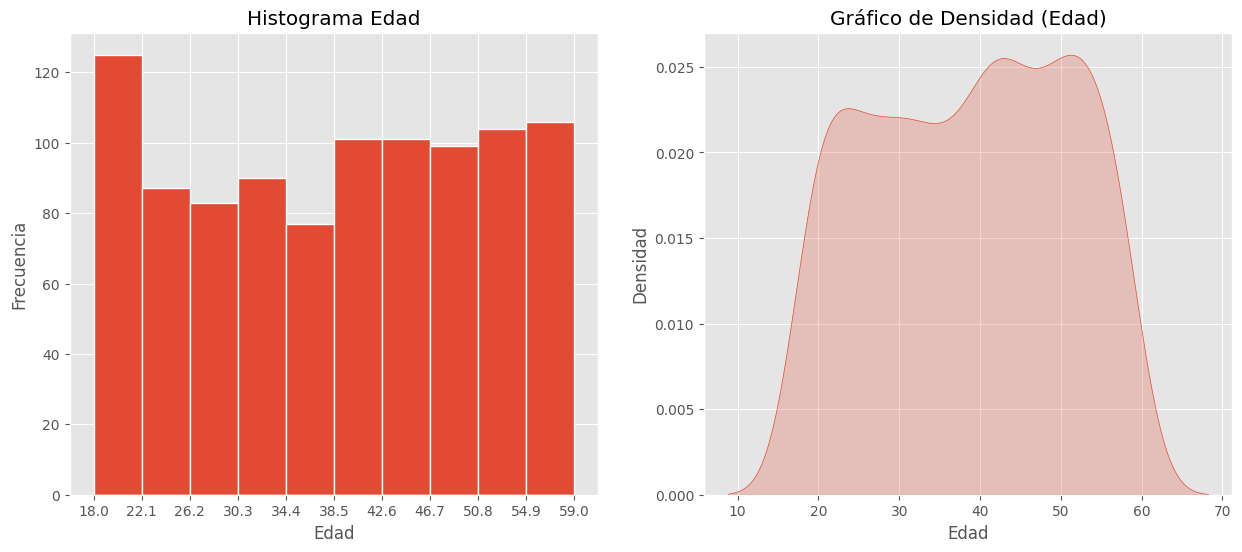

In [8]:
fig, ax = plt.subplots(1,2, figsize=(15, 6))

# Datos de 'Age' del dataframe
age = df['Age']

# Crear los rangos de forma 'proporcional' para el histograma
min_valor = df['Age'].min()
max_valor = df['Age'].max()
num_bins = 10
bins = np.linspace(min_valor, max_valor, num_bins + 1)

# Histograma para los datos 'Age'
ax[0].hist(age, bins=bins, linewidth=1, edgecolor="white")
ax[0].set_xticks(bins)

# Titulo de grafico y ejes
ax[0].set_title("Histograma Edad")
ax[0].set_xlabel("Edad")
ax[0].set_ylabel("Frecuencia")

# Grafico de densidad para la variable 'Age'
sns.kdeplot(df['Age'], fill=True)

# Titulo de grafico y ejes
ax[1].set_title("Gráfico de Densidad (Edad)")
ax[1].set_xlabel("Edad")
ax[1].set_ylabel("Densidad")

Text(0.5, 0, 'Edad')

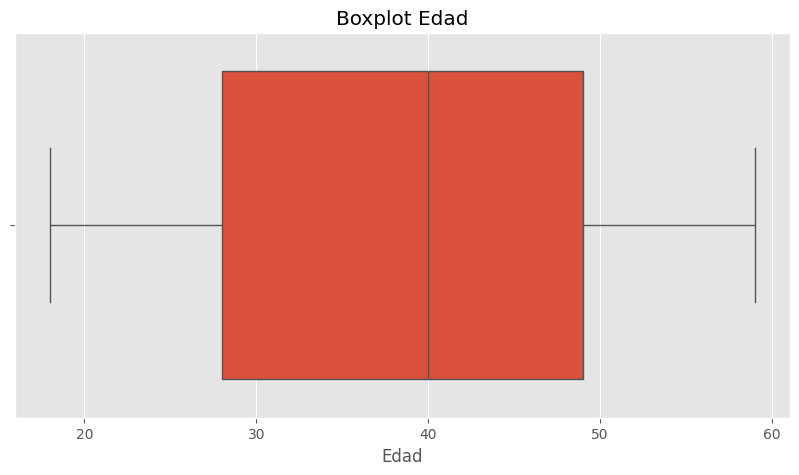

In [9]:
fig = plt.subplots(figsize=(10, 5))

# Grafico 'Boxplot' para la variable 'Age'
sns.boxplot(df['Age'],orient='h', saturation=0.9)
plt.title('Boxplot Edad')
plt.xlabel('Edad')

* Análisis para la variable - 'Weight (kg)'

In [10]:
# Medidad de tendencia del dato 'Weight(Kg)'
df['Weight (kg)'].describe()

,Weight (kg)
count,973.000000
mean,73.854676
std,21.207500
min,40.000000
25%,58.100000
50%,70.000000
75%,86.000000
max,129.900000


Text(0, 0.5, 'Densidad')

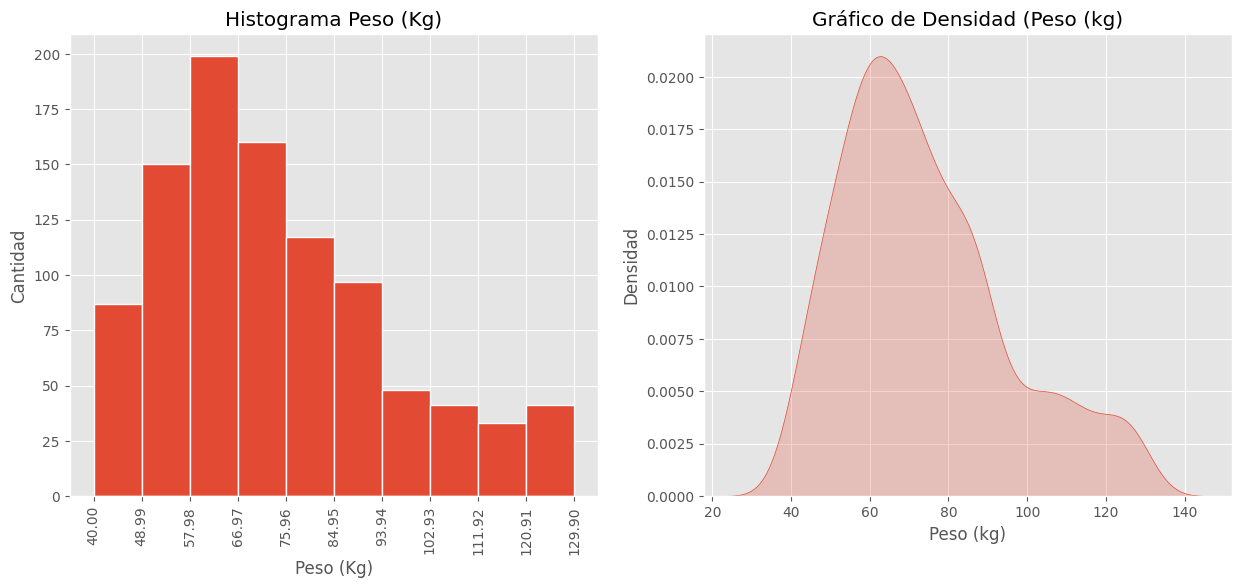

In [11]:
fig, ax = plt.subplots(1,2, figsize=(15, 6))

# Variable 'Weight' del dataframe
weight = df['Weight (kg)']

# Crear los rangos de forma 'proporcional' para el histograma
min_valor = df['Weight (kg)'].min()
max_valor = df['Weight (kg)'].max()
num_bins = 10
bins = np.linspace(min_valor, max_valor, num_bins + 1)

# Histograma para los datos 'Weight'
ax[0].hist(weight, bins=bins, linewidth=1, edgecolor="white")
ax[0].set_xticks(bins)
ax[0].set_xticklabels([f'{x:.2f}' for x in bins], rotation=90)

# Titulo de grafico y ejes
ax[0].set_title("Histograma Peso (Kg)")
ax[0].set_xlabel("Peso (Kg)")
ax[0].set_ylabel("Cantidad")

# Grafico de densidad
sns.kdeplot(df['Weight (kg)'], fill=True)

# Titulo de grafico y ejes
ax[1].set_title("Gráfico de Densidad (Peso (kg)")
ax[1].set_xlabel("Peso (kg)")
ax[1].set_ylabel("Densidad")

Text(0.5, 0, 'Peso')

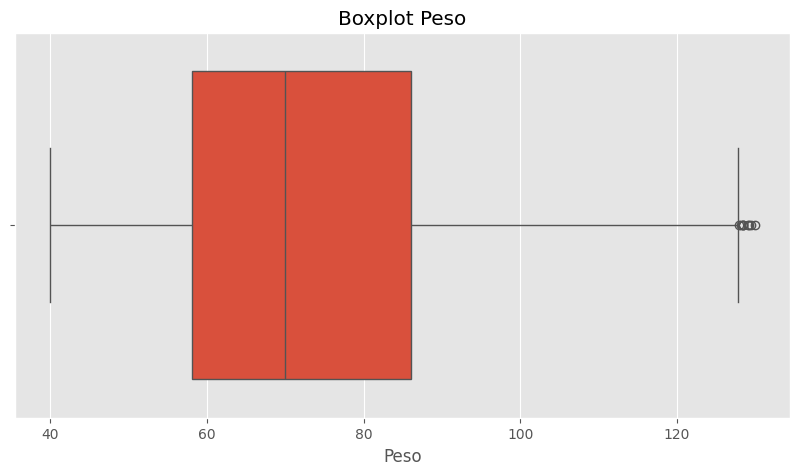

In [12]:
fig = plt.subplots(figsize=(10, 5))

# Grafico 'Boxplot' para la variable 'Weight'
sns.boxplot(df['Weight (kg)'],orient='h', saturation=0.9)
plt.title('Boxplot Peso')
plt.xlabel('Peso')

* Análisis para la variable - 'Height (m)'

In [13]:
df['Height (m)'].describe()

,Height (m)
count,973.00000
mean,1.72258
std,0.12772
min,1.50000
25%,1.62000
50%,1.71000
75%,1.80000
max,2.00000


Text(0, 0.5, 'Densidad')

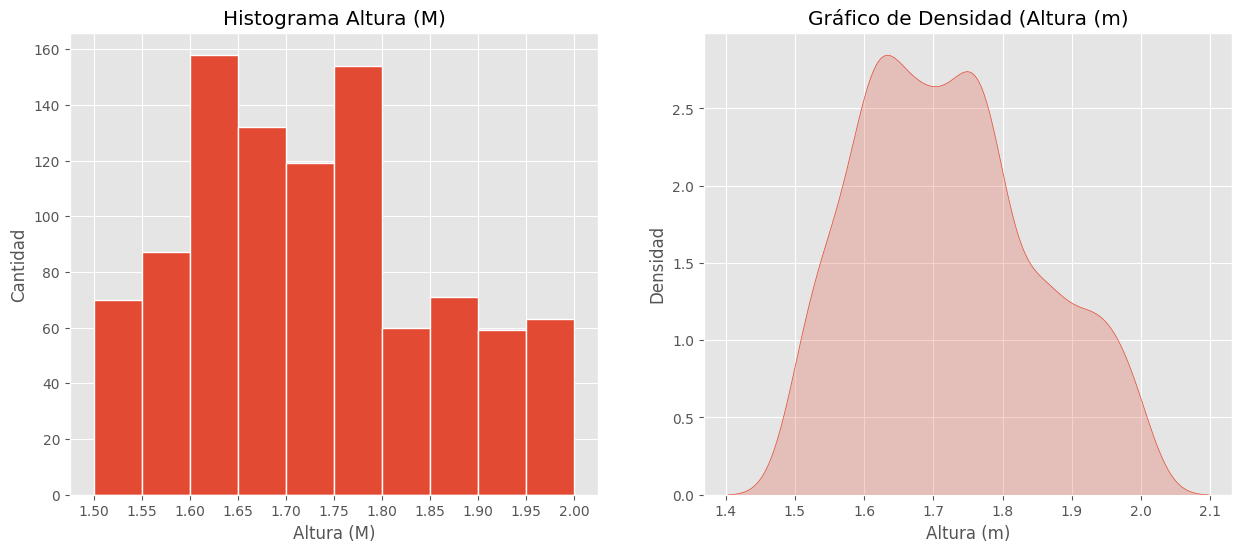

In [14]:
fig, ax = plt.subplots(1,2, figsize=(15, 6))

# Variable 'Height' del dataframe
height = df['Height (m)']

# Crear los rangos de forma 'proporcional' para el histograma
min_valor = df['Height (m)'].min()
max_valor = df['Height (m)'].max()
num_bins = 10
bins = np.linspace(min_valor, max_valor, num_bins + 1)

# Histograma para los datos 'Height'
ax[0].hist(height, bins=bins, linewidth=1, edgecolor="white")
ax[0].set_xticks(bins);

# Titulo de grafico y ejes
ax[0].set_title("Histograma Altura (M)")
ax[0].set_xlabel("Altura (M)")
ax[0].set_ylabel("Cantidad")

# Grafico de densidad de los datos 'Height'
sns.kdeplot(df['Height (m)'], fill=True)
ax[1].set_title("Gráfico de Densidad (Altura (m)")
ax[1].set_xlabel("Altura (m)")
ax[1].set_ylabel("Densidad")

Text(0.5, 0, 'Altura')

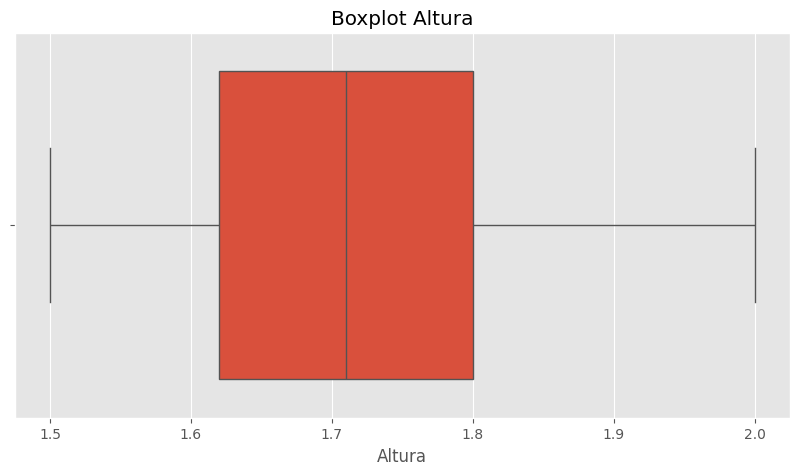

In [15]:
fig = plt.subplots(figsize=(10, 5))

# Grafico 'Boxplot' de los datos 'Height'
sns.boxplot(df['Height (m)'],orient='h', saturation=0.9)
plt.title('Boxplot Altura')
plt.xlabel('Altura')

* Análisis para la variable - 'Gender'

In [16]:
df['Gender'].describe()

,Gender
count,973
unique,2
top,Male
freq,511


(0.0, 30.92001174168297)

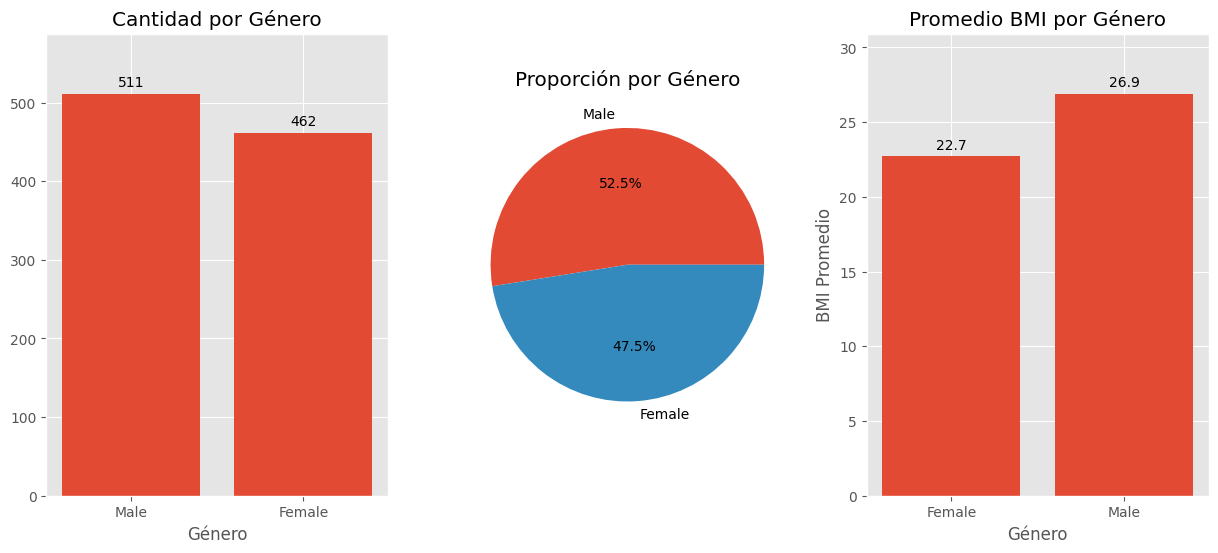

In [17]:
fig, axs = plt.subplots(1,3, figsize=(15, 6))

# Datos de 'Gender' del dataframe
gender = df['Gender']
counts = gender.value_counts()
bmi_by_gender = df.groupby('Gender')['BMI'].mean()

# Grafico de barras para la variable 'Gender'
bars = axs[0].bar(counts.index, counts.values)
axs[0].set_title("Cantidad por Género")
axs[0].set_xlabel("Género")

# Agrega etiquetas
axs[0].bar_label(bars, labels=[str(v) for v in counts.values], padding=3)

# Asegurar espacio superior para que no se corten las etiquetas
axs[0].set_ylim(0, counts.values.max() * 1.15)

# Grafico de pastel para la variable 'Gender'
axs[1].pie(counts, labels=counts.index, autopct='%1.1f%%')
axs[1].set_title("Proporción por Género")

# Grafico de barras BMI
bars = axs[2].bar(bmi_by_gender.index, bmi_by_gender.values)

# Titulo de grafico y ejes
axs[2].set_title("Promedio BMI por Género")
axs[2].set_xlabel("Género")
axs[2].set_ylabel("BMI Promedio")

# Etiqueta de datos
axs[2].bar_label(bars, fmt='%1.1f', padding=3)
axs[2].set_ylim(0, bmi_by_gender.max() * 1.15)

/tmp/ipython-input-1768263328.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Workout_Type', data=df, palette='crest', order=df['Workout_Type'].value_counts().index, ax=axs[0])


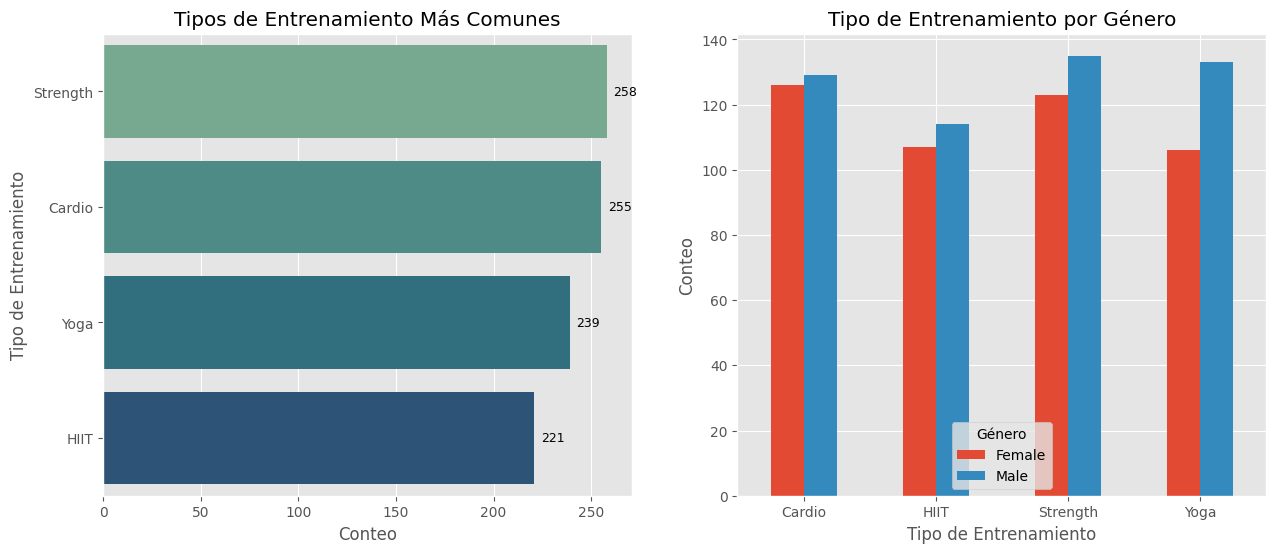

In [24]:
fig, axs = plt.subplots(1,2, figsize=(15, 6))

# Grafico de barras para Tipos de Entrenamiento Más Comunes
sns.countplot(y='Workout_Type', data=df, palette='crest', order=df['Workout_Type'].value_counts().index, ax=axs[0])

# Titulo de grafico y ejes
axs[0].set_title('Tipos de Entrenamiento Más Comunes')
axs[0].set_xlabel('Conteo')
axs[0].set_ylabel('Tipo de Entrenamiento')

# Agregar las etiquetas de datos
total = len(df)
for p in axs[0].patches:
    width = p.get_width()
    y = p.get_y() + p.get_height() / 2
    axs[0].annotate(
        f"{int(width):,}",
        xy=(width, y),
        xytext=(5, 0),
        textcoords="offset points",
        ha='left', va='center',
        fontsize=9,
        clip_on=False
    )

# Grafico de barras para Tipo de Entrenamiento por Género
contingency_table = df.groupby('Workout_Type')['Gender'].value_counts().unstack()
contingency_table.plot(kind='bar', stacked=False, ax=axs[1])

# Titulo de grafico y ejes
axs[1].set_title('Tipo de Entrenamiento por Género')
axs[1].set_xlabel('Tipo de Entrenamiento')
axs[1].set_ylabel('Conteo')
plt.xticks(rotation=0, ha='center')
plt.legend(title='Género', loc='lower center')

### Análisis Bivariado y Multivariado

El análisis se enfoca en explorar la relación entre variables. Su objetivo es identificar asociaciones, correlaciones o patrones que existan entre ellas.

Text(0, 0.5, 'Conteo')

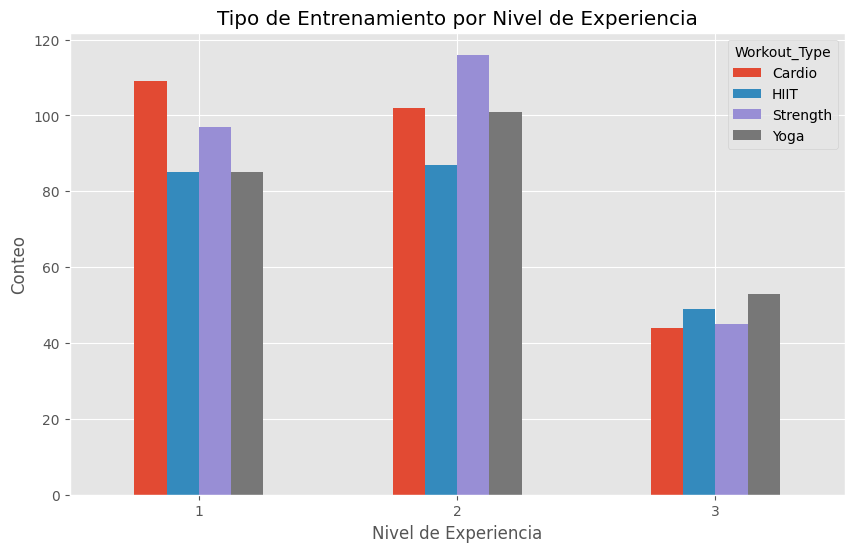

In [19]:
fig, ax = plt.subplots()

# Grafico de barras agrupadas para el tipo de entramiento segun la experiencia
experience_workout = df.groupby('Experience_Level')['Workout_Type'].value_counts().unstack()
experience_workout.plot(kind='bar',stacked=False, ax=ax)
plt.xticks(rotation=0, ha='center')

# Titulo de grafico y ejes
ax.set_title('Tipo de Entrenamiento por Nivel de Experiencia')
ax.set_xlabel('Nivel de Experiencia')
ax.set_ylabel('Conteo')

(0.0, 1469.2039215686273)

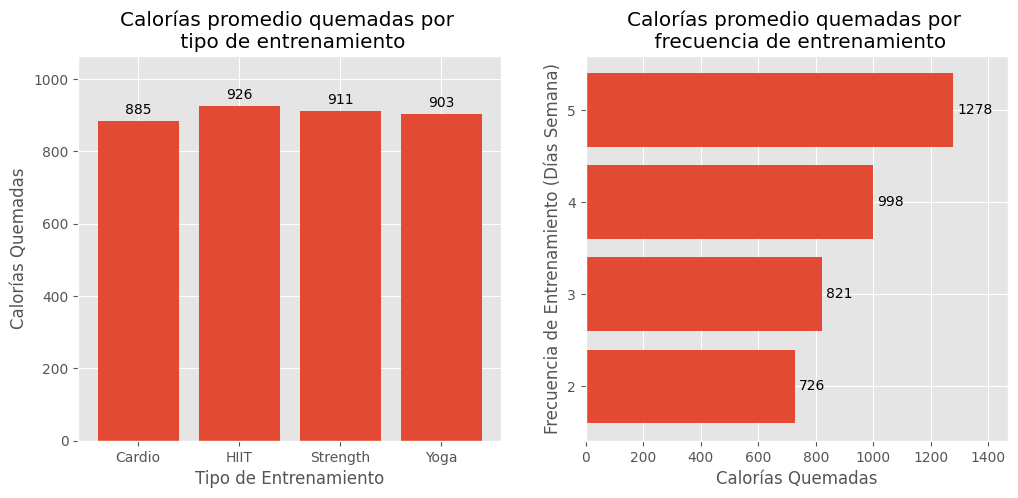

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Datos originales
calories = df['Calories_Burned']
workout = df['Workout_Type']
frequency = df['Workout_Frequency (days/week)']

# Agrupar por tipo de entrenamiento
cal_by_workout = df.groupby('Workout_Type')['Calories_Burned'].mean()
bars1 = axs[0].bar(cal_by_workout.index, cal_by_workout.values)

# Titulo de grafico y ejes
axs[0].set_title("Calorías promedio quemadas por \n tipo de entrenamiento")
axs[0].set_ylabel("Calorías Quemadas")
axs[0].set_xlabel("Tipo de Entrenamiento")

# Etiquetas de valores
axs[0].bar_label(bars1, fmt='%.0f', padding=3)
axs[0].set_ylim(0, cal_by_workout.max() * 1.15)

# Agrupar por frecuencia de entrenamiento (ordenar por frecuencia)
cal_by_freq = df.groupby('Workout_Frequency (days/week)')['Calories_Burned'].mean()
bars2 = axs[1].barh(cal_by_freq.index.astype(str), cal_by_freq.values)

# Titulo de grafico y ejes
axs[1].set_title("Calorías promedio quemadas por \n frecuencia de entrenamiento")
axs[1].set_ylabel("Frecuencia de Entrenamiento (Días Semana)")
axs[1].set_xlabel("Calorías Quemadas")

# Etiquetas de valores
axs[1].bar_label(bars2, fmt='%.0f', padding=3)
axs[1].set_xlim(0, cal_by_freq.max() * 1.15)

Text(0.5, 0, 'Calorias Quemadas por Sesion de Entrenamiento')

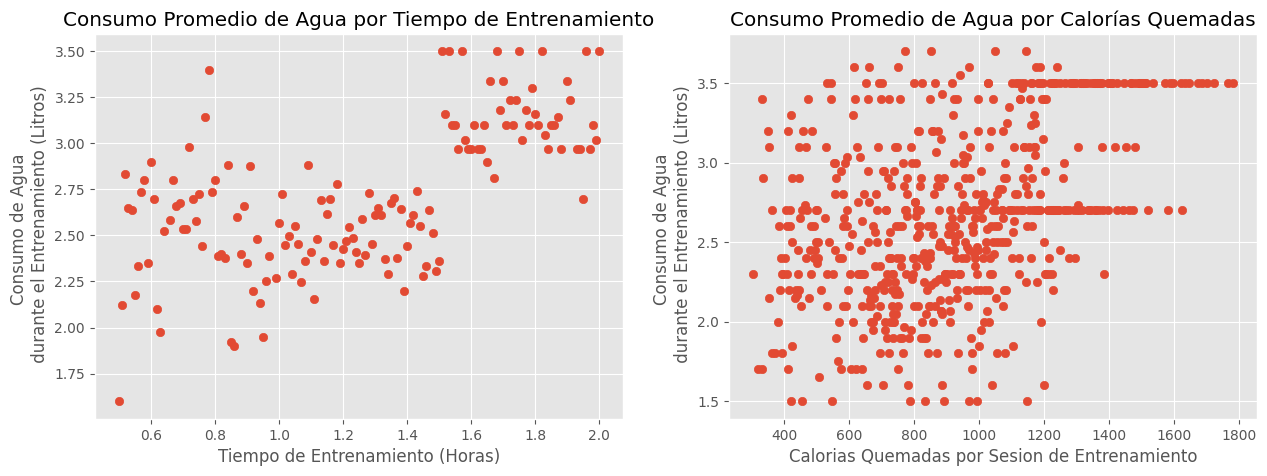

In [38]:
fig, ax = plt.subplots(1,2, figsize=(15, 5))

# Datos originales
fat_water = df.groupby('Session_Duration (hours)')['Water_Intake (liters)'].mean()
x = fat_water.index
y = fat_water.values

# Grafico de dispersión para el consumo de agua promedio por tiempo de entrenamiento
ax[0].scatter(x,y)

# Titulo de grafico y ejes
ax[0].set_title('Consumo Promedio de Agua por Tiempo de Entrenamiento')
ax[0].set_ylabel('Consumo de Agua \n durante el Entrenamiento (Litros)')
ax[0].set_xlabel('Tiempo de Entrenamiento (Horas)')

calories_water = df.groupby('Calories_Burned')['Water_Intake (liters)'].mean()
x2 = calories_water.index
y2 = calories_water.values

# Grafico de dispersión para el
ax[1].scatter(x2,y2)

# Titulo de grafico y ejes
ax[1].set_title('Consumo Promedio de Agua por Calorías Quemadas')
ax[1].set_ylabel('Consumo de Agua \n durante el Entrenamiento (Litros)')
ax[1].set_xlabel('Calorias Quemadas por Sesion de Entrenamiento')

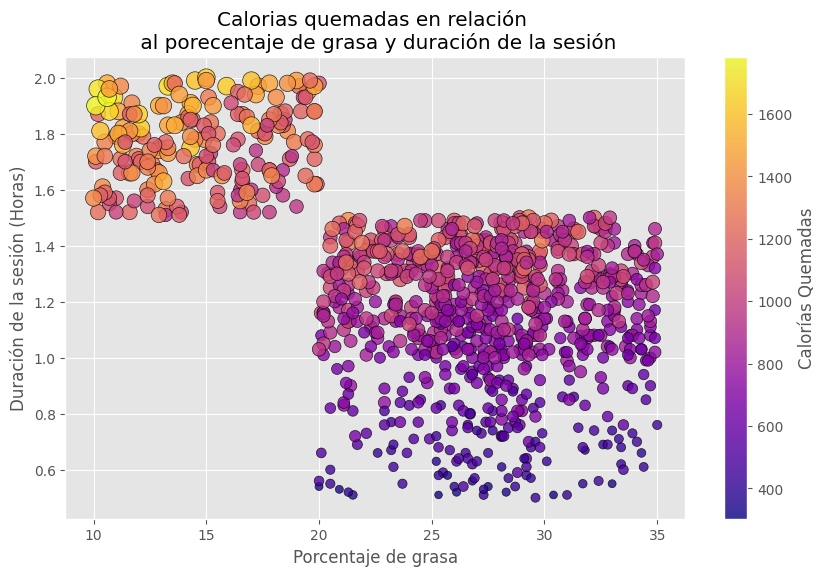

In [22]:
fig, ax = plt.subplots()

# Datos originales del Dataset
calories = df['Calories_Burned']
session = df['Session_Duration (hours)']
fat_perc = df['Fat_Percentage']

# Grafico de Dispersión
scatter = ax.scatter(fat_perc, session, s=calories*0.1, c=calories, cmap='plasma', alpha=0.8, edgecolors='black')

# Titulo grafico y ejes
ax.set_title('Calorias quemadas en relación \n al porecentaje de grasa y duración de la sesión')
ax.set_xlabel('Porcentaje de grasa')
ax.set_ylabel('Duración de la sesión (Horas)')

cbar = fig.colorbar(scatter, ax=ax, orientation='vertical')
cbar.set_label('Calorías Quemadas')

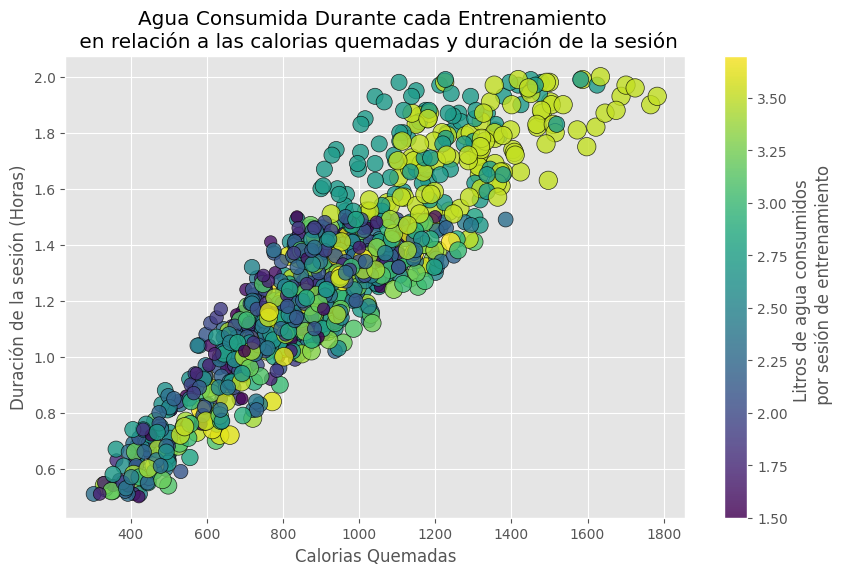

In [69]:
fig, ax = plt.subplots()

# Datos originales del Dataset
calories = df['Water_Intake (liters)']
session = df['Session_Duration (hours)']
bmi = df['Calories_Burned']

# Grafico de Dispersión
scatter = ax.scatter(bmi, session, s=calories*50, c=calories, cmap='viridis', alpha=0.8, edgecolors='black')

# Titulo grafico y ejes
ax.set_title('Agua Consumida Durante cada Entrenamiento \n en relación a las calorias quemadas y duración de la sesión')
ax.set_xlabel('Calorias Quemadas')
ax.set_ylabel('Duración de la sesión (Horas)')

cbar = fig.colorbar(scatter, ax=ax, orientation='vertical')
cbar.set_label('Litros de agua consumidos \n por sesión de entrenamiento')

## **Conclusiones y Recomendaciones**

### 1. Conclusiones

A partir del EDA sobre las 973 observaciones del dataset se extraen las siguientes conclusiones:

- **Distribución por tipo de entrenamiento:** El entrenamiento **de fuerza** es el más frecuente (258 registros), seguido muy de cerca por **cardio** (255 registros). Esto indica una preferencia equilibrada entre fuerza y acondicionamiento en el Dataset.

- **Diferencias por género:** Los **hombres** prefieren mayoritariamente entrenamientos de **fuerza**, seguido de **yoga**; las **mujeres** muestran preferencia por **cardio**, con **fuerza** en segundo lugar. Estas diferencias sugieren segmentaciones útiles para programas y comunicación personalizada.

- **Patrones por nivel de experiencia:**  
  - **Principiantes (nivel 1):** predominio de **cardio**, seguido de fuerza.  
  - **Intermedios (nivel 2):** predominio de **fuerza**, con cardio y yoga en conteos muy similares.  
  - **Avanzados (nivel 3):** distribución más homogénea, con una ligera preferencia por **yoga**.  
  Esto indica que la experiencia influye en la selección de modalidades y puede orientar la oferta de programas por nivel.

- **Gasto calórico por tipo de entrenamiento:** Las medias de calorías por sesión son similares entre entrenamientos: **Cardio ≈ 885**, **Yoga ≈ 903**, **Fuerza ≈ 911**, **HIIT ≈ 926**. No se observa una diferencia práctica significativa en las calorías quemadas promedio por tipo de entrenamiento en el Dataset.

- **Gasto calórico según frecuencia semanal:** Existe un incremento marcado del gasto medio de calorias por sesión al aumentar la frecuencia semanal: **2 días → 726**, **3 días → 821**, **4 días → 998**, **5 días → 1278**. El salto entre 4 y 5 días es especialmente notable, lo que sugiere que mayor frecuencia semanal se asocia a sesiones con mayor gasto energético medio.

- **Relación grasa corporal — duración y calorías:** Personas con **Porcentaje de grasa entre 20% y 35%** queman menos calorías en relación con quienes tienen **10%–19%**; además, las personas con un porcentaje menor realizan sesiones más largas (≈1.5–2 h). Esto puede reflejar mayor intensidad y con ello mayor calorias quemadas a diferencia de las personas con mayor grasa; sin embargo, la observación puede estar afectada por factores externos (salud, condición física, equipamiento) no contemplados en el dataset.

- **Hidratación y desempeño:** Los consumos de agua más altos (≈**2.75–3.5 L**) se asocian a duraciones de sesión más largas (≈1.5–2 h) y mayores rangos de calorías quemadas (≈1000–1800). Esto sugiere que un mayor consumo de agua aparece como un factor relacionado con sesiones más largas y mayor gasto, aunque no prueba causalidad.

- Los hallazgos son útiles para segmentación y diseño de intervenciones, pero su interpretación debe ser prudente debido a variables no medidas y posible sesgo de autoinforme.

---

### 2. Recomendaciones

A continuación se presentan recomendaciones accionables derivadas de las conclusiones del EDA.

## Para la gerencia / producto
- **Segmentación de oferta:** Crear programas y paquetes dirigidos por objetivo y género:
  - Paquetes para pérdida de grasa y acondicionamiento (Cardio + HIIT) dirigidos a quienes prefieren cardio.
  - Programas de fuerza y de fuerza+recuperación dirigidos a la mayoría masculina que prefiere fuerza.
- **Programas por nivel de experiencia:** Ofrecer 3 rutas claras (Principiantes / Intermedios / Avanzados) con metas semanales y progresión para aumentar adherencia.
- **Promover frecuencia objetivo:** Incentivar metas de entrenamiento de **3–5 días/semana**, con especial atención a programas que ayuden a alcanzar 4→5 días porque se asocia a mayor gasto energético.
- **Mejoras en la recolección de datos:** Añadir mas datos de usuario, timestamps por sesión, dispositivo de medición y campos de estado de salud/medicación, etc (opcionales y confidenciales).

## Para usuarios / miembros
- **Priorizar consistencia:** Fijar meta inicial de 3 sesiones/semana y escalar a 4–5 para ver aumentos de gasto calórico promedio.  
- **Hidratación:** Mantener ingestas razonables antes/durante sesión; la muestra sugiere que consumos ~2.75–3.5 L se asocian a sesiones más largas (consultar si aplica por salud).  
- **Seguridad:** Si se tiene alto porcentaje de grasa o condiciones médicas, consultar profesional de salud antes de aumentar intensidad o frecuencia.

## Notas de seguridad
- Evitar recomendaciones médicas directas. Para usuarios con condiciones médicas o altos porcentajes de grasa, derivar a profesionales de la salud.  
- Si se recogen datos sensibles (salud, patologías), asegurar consentimiento y cumplimiento de privacidad.

